In [2]:
# Import all required libraries for data analysis, visualization and machine learning

import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.inspection import permutation_importance

from statsmodels.stats.outliers_influence import variance_inflation_factor

import warnings
warnings.filterwarnings("ignore")

sns.set_theme()

In [3]:
# Load the house price dataset

df = pd.read_csv("../data/house_price.csv")

df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [4]:
# Load the house price dataset

df = pd.read_csv("../data/house_price.csv")

df.head()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


In [5]:
# Display all column names

print(df.columns.tolist())

['Id', 'Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location', 'Condition', 'Garage', 'Price']


In [6]:
# Check data types and non-null values

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 10 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Id         2000 non-null   int64
 1   Area       2000 non-null   int64
 2   Bedrooms   2000 non-null   int64
 3   Bathrooms  2000 non-null   int64
 4   Floors     2000 non-null   int64
 5   YearBuilt  2000 non-null   int64
 6   Location   2000 non-null   str  
 7   Condition  2000 non-null   str  
 8   Garage     2000 non-null   str  
 9   Price      2000 non-null   int64
dtypes: int64(7), str(3)
memory usage: 184.3 KB


In [7]:
# Generate descriptive statistics for numerical columns

df.describe()

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000,2000.000000
mean,1000.500000,2786.209500,3.003500,2.55250,1.993500,1961.446000,537676.855000
std,577.494589,1295.146799,1.424606,1.10899,0.809188,35.926695,276428.845719
min,1.000000,501.000000,1.000000,1.00000,1.000000,1900.000000,50005.000000
25%,500.750000,1653.000000,2.000000,2.00000,1.000000,1930.000000,300098.000000
50%,1000.500000,2833.000000,3.000000,3.00000,2.000000,1961.000000,539254.000000
75%,1500.250000,3887.500000,4.000000,4.00000,3.000000,1993.000000,780086.000000
max,2000.000000,4999.000000,5.000000,4.00000,3.000000,2023.000000,999656.000000


In [8]:
# Display the first and last five records

display(df.head())
display(df.tail())

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
0,1,1360,5,4,3,1970,Downtown,Excellent,No,149919
1,2,4272,5,4,3,1958,Downtown,Excellent,No,424998
2,3,3592,2,2,3,1938,Downtown,Good,No,266746
3,4,966,4,2,2,1902,Suburban,Fair,Yes,244020
4,5,4926,1,4,2,1975,Downtown,Fair,Yes,636056


,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Location,Condition,Garage,Price
1995,1996,4994,5,4,3,1923,Suburban,Poor,No,295620
1996,1997,3046,5,2,1,2019,Suburban,Poor,Yes,580929
1997,1998,1062,5,1,2,1903,Rural,Poor,No,476925
1998,1999,4062,3,1,2,1936,Urban,Excellent,Yes,161119
1999,2000,2989,5,1,3,1903,Suburban,Fair,No,482525


In [9]:
# Calculate the percentage of missing values in every column

missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage.sort_values(ascending=False))

Id           0.0
Area         0.0
Bedrooms     0.0
Bathrooms    0.0
Floors       0.0
YearBuilt    0.0
Location     0.0
Condition    0.0
Garage       0.0
Price        0.0
dtype: float64


In [10]:
# Check for duplicate rows

print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [11]:
# Check unique values of categorical columns

print("Location values:")
print(df["Location"].unique())

print("\nCondition values:")
print(df["Condition"].unique())

Location values:
<ArrowStringArray>
['Downtown', 'Suburban', 'Urban', 'Rural']
Length: 4, dtype: str

Condition values:
<ArrowStringArray>
['Excellent', 'Good', 'Fair', 'Poor']
Length: 4, dtype: str


In [12]:
# Count the number of houses in each categorical category

print(df["Location"].value_counts())
print()
print(df["Condition"].value_counts())

Location
Downtown    558
Urban       485
Suburban    483
Rural       474
Name: count, dtype: int64

Condition
Fair         521
Excellent    511
Poor         507
Good         461
Name: count, dtype: int64


In [13]:
# Check minimum and maximum values of numerical columns

numeric_columns = [
    "Area",
    "Bedrooms",
    "Bathrooms",
    "Floors",
    "YearBuilt",
    "Garage",
    "Price"
]

df[numeric_columns].agg(["min", "max"])

,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Garage,Price
min,501,1,1,1,1900,No,50005
max,4999,5,4,3,2023,Yes,999656


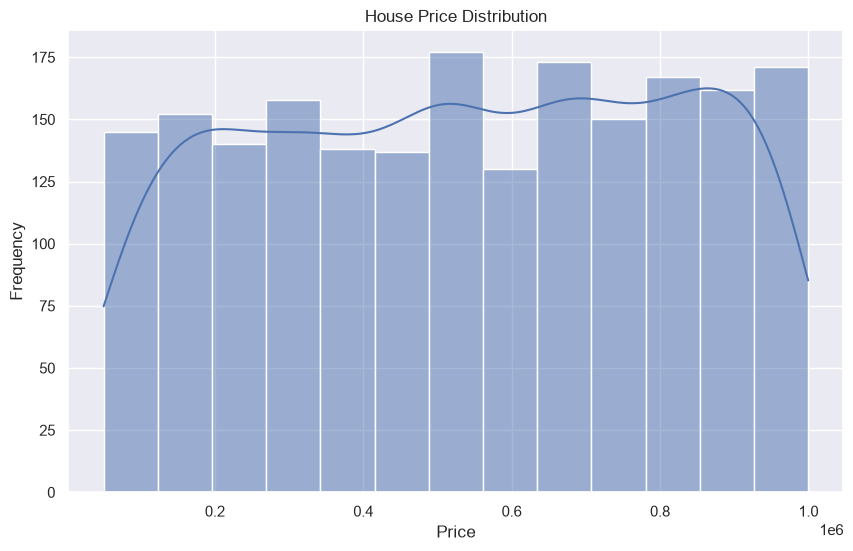

In [14]:
# Visualize the distribution of house prices

plt.figure(figsize=(10, 6))
sns.histplot(df["Price"], kde=True)
plt.title("House Price Distribution")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.show()

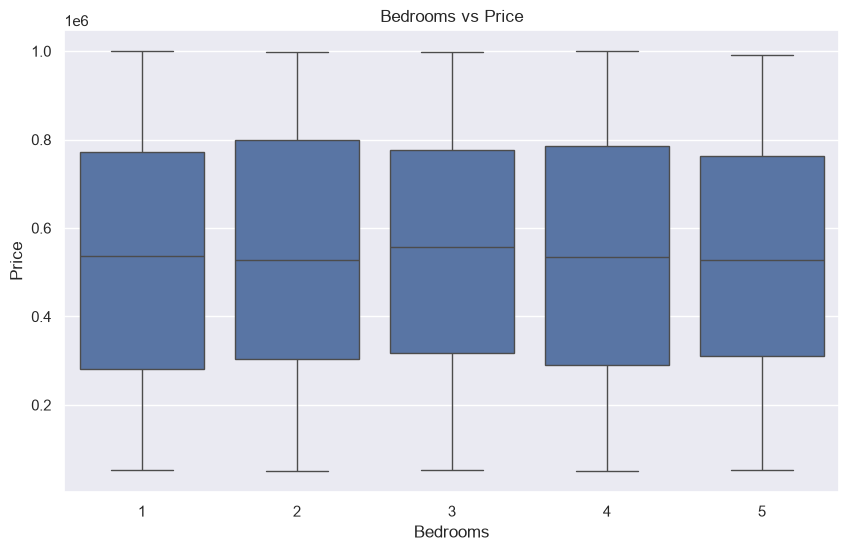

In [15]:
# Compare house prices across different bedroom counts

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Bedrooms", y="Price")
plt.title("Bedrooms vs Price")
plt.show()

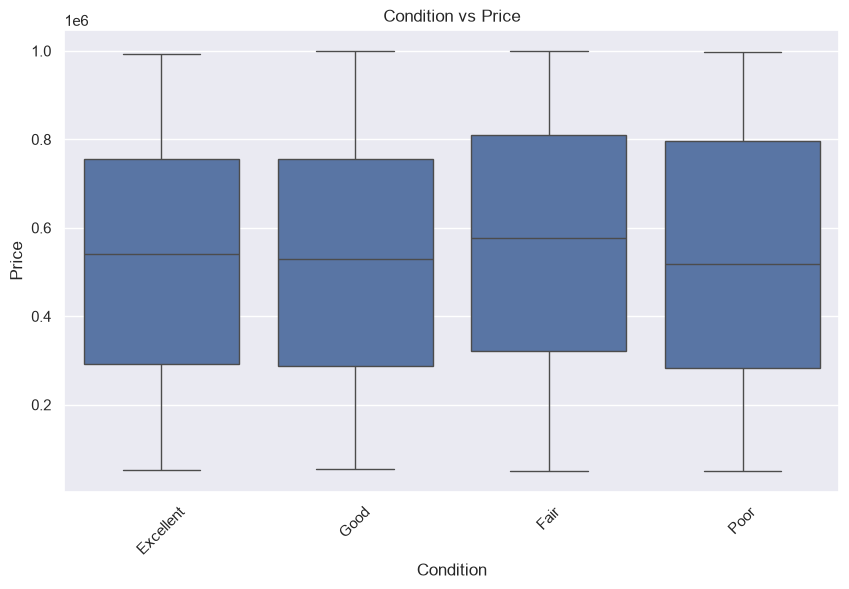

In [16]:
# Compare house prices across different house conditions

plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="Condition", y="Price")
plt.title("Condition vs Price")
plt.xticks(rotation=45)
plt.show()

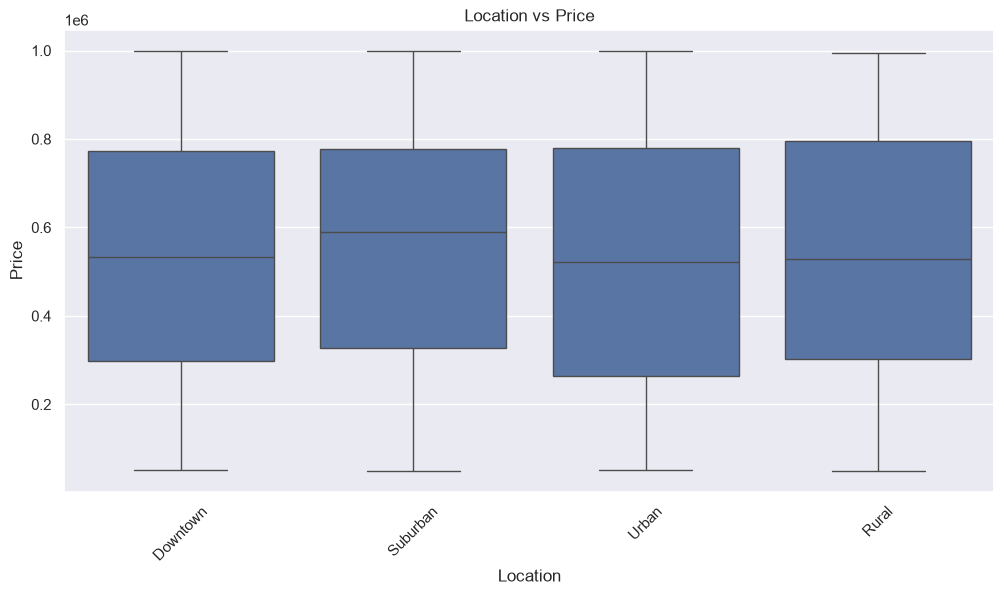

In [17]:
# Compare house prices across different locations

plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="Location", y="Price")
plt.title("Location vs Price")
plt.xticks(rotation=45)
plt.show()

In [18]:
# Calculate correlations between numerical variables

correlation = df.corr(numeric_only=True)

correlation

,Id,Area,Bedrooms,Bathrooms,Floors,YearBuilt,Price
Id,1.000000,-0.012966,-0.016393,-0.025433,-0.002025,0.008840,-0.025643
Area,-0.012966,1.000000,0.047523,0.021881,0.017749,-0.011609,0.001542
Bedrooms,-0.016393,0.047523,1.000000,-0.011990,0.010435,-0.014125,-0.003471
Bathrooms,-0.025433,0.021881,-0.011990,1.000000,0.029089,-0.000839,-0.015737
Floors,-0.002025,0.017749,0.010435,0.029089,1.000000,-0.006474,0.055890
YearBuilt,0.008840,-0.011609,-0.014125,-0.000839,-0.006474,1.000000,0.004845
Price,-0.025643,0.001542,-0.003471,-0.015737,0.055890,0.004845,1.000000


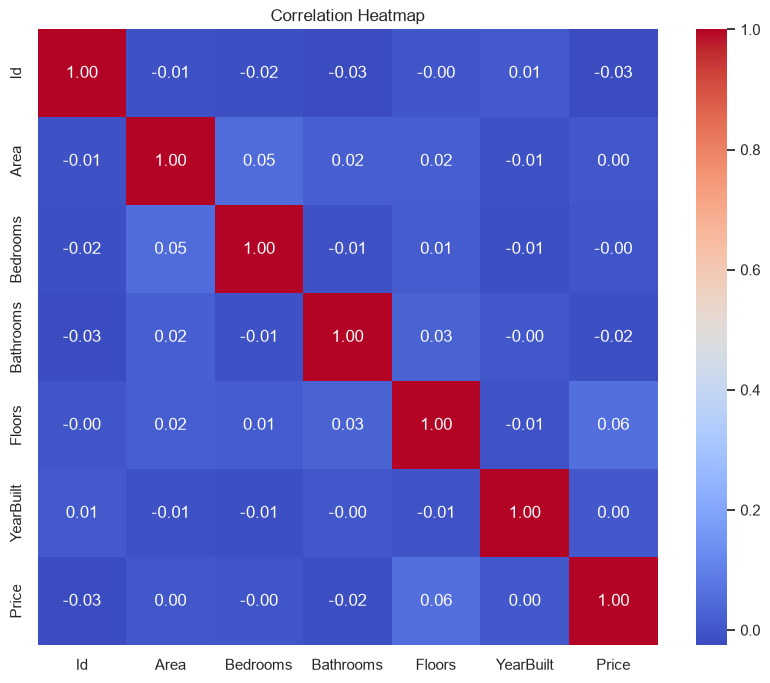

In [19]:
# Visualize numerical correlations using a heatmap

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

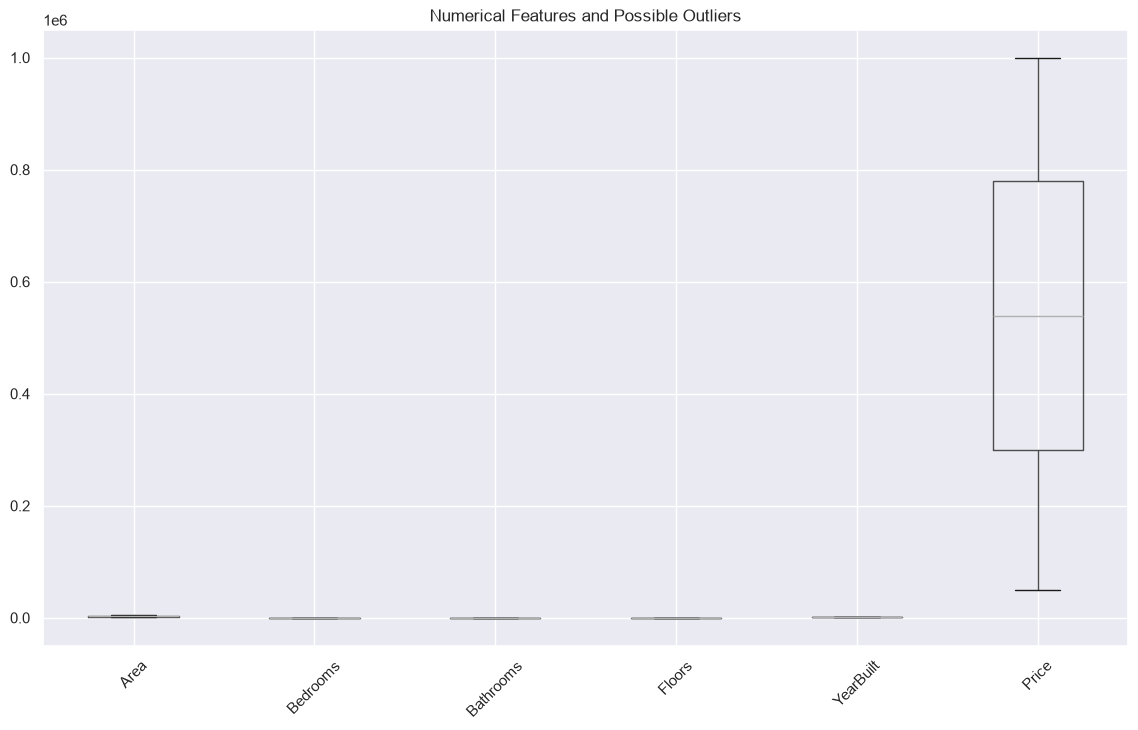

In [20]:
# Visualize possible outliers in numerical columns

plt.figure(figsize=(14, 8))

df[numeric_columns].boxplot()

plt.xticks(rotation=45)
plt.title("Numerical Features and Possible Outliers")
plt.show()

In [21]:
def find_outliers_iqr(data, column):
    # Convert PyArrow types to standard NumPy float64 for calculations
    col_data = data[column].to_numpy(dtype="float64", na_value=float("nan"))

    # Use NumPy's nanquantile to safely ignore missing values
    import numpy as np

    Q1 = np.nanquantile(col_data, 0.25)
    Q3 = np.nanquantile(col_data, 0.75)

    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Filter original dataframe using the numpy bounds
    outliers = data[(data[column] < lower_bound) | (data[column] > upper_bound)]
    return outliers, lower_bound, upper_bound


In [22]:
# Create a new feature representing the approximate age of the house

CURRENT_YEAR = 2026

df["HouseAge"] = CURRENT_YEAR - df["YearBuilt"]

df[["YearBuilt", "HouseAge"]].head()

,YearBuilt,HouseAge
0,1970,56
1,1958,68
2,1938,88
3,1902,124
4,1975,51


In [23]:
# Create a simple combined feature from bedrooms and bathrooms

df["TotalRooms"] = df["Bedrooms"] + df["Bathrooms"]

df[["Bedrooms", "Bathrooms", "TotalRooms"]].head()

,Bedrooms,Bathrooms,TotalRooms
0,5,4,9
1,5,4,9
2,2,2,4
3,4,2,6
4,1,4,5


In [24]:
# Create a feature representing area available per bedroom

df["AreaPerBedroom"] = df["Area"] / df["Bedrooms"].replace(0, np.nan)

df["AreaPerBedroom"] = df["AreaPerBedroom"].fillna(
    df["AreaPerBedroom"].median()
)

df[["Area", "Bedrooms", "AreaPerBedroom"]].head()

,Area,Bedrooms,AreaPerBedroom
0,1360,5,272.0
1,4272,5,854.4
2,3592,2,1796.0
3,966,4,241.5
4,4926,1,4926.0


In [25]:
# Remove the identifier column because it does not represent house characteristics

df = df.drop(columns=["Id"])

In [26]:
# Separate input features from the target price

X = df.drop(columns=["Price"])
y = df["Price"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['Area', 'Bedrooms', 'Bathrooms', 'Floors', 'YearBuilt', 'Location', 'Condition', 'Garage', 'HouseAge', 'TotalRooms', 'AreaPerBedroom']

Target:
Price


In [27]:
# # Demonstrate label encoding for a categorical variable

# label_encoder = LabelEncoder()

# condition_encoded = label_encoder.fit_transform(df["Condition"])

# print("Original:")
# print(df["Condition"].head())

# print("\nEncoded:")
# print(condition_encoded[:5])

In [28]:
# Split the dataset into training, validation and testing sets

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (1400, 11)
Validation: (300, 11)
Testing: (300, 11)


In [29]:
# Separate numerical and categorical input columns

numeric_features = [
    "Area",
    "Bedrooms",
    "Bathrooms",
    "Floors",
    "YearBuilt",
    "HouseAge",
    "TotalRooms",
    "AreaPerBedroom"
]

categorical_features = [
    "Location",
    "Condition",
    "Garage"
]

In [30]:
# Create a OneHotEncoder that ignores unseen categories during prediction

one_hot_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [31]:
# Demonstrate standard scaling on numerical training data

scaler = StandardScaler()

X_train_numeric = X_train[numeric_features]

X_train_scaled = scaler.fit_transform(X_train_numeric)

X_train_scaled[:5]

array([[ 0.05864822,  0.68897439, -0.47602618, -1.2338974 , -1.33461035,
         1.33461035,  0.25159977, -0.50849511],
       [-0.48268276, -1.42166925,  1.32272321,  0.00442257,  0.93986588,
        -0.93986588, -0.30751083,  0.8364015 ],
       [ 0.44366315,  1.39252227, -0.47602618, -1.2338974 , -0.30832229,
         0.30832229,  0.81071037, -0.54888142],
       [-1.01015321, -0.71812137, -0.47602618,  1.24274254, -1.41782289,
         1.41782289, -0.86662144, -0.48647042],
       [-0.52965458,  0.68897439, -0.47602618, -1.2338974 ,  0.46832813,
        -0.46832813,  0.25159977, -0.68561991]])

In [32]:
# Create separate preprocessing steps for numerical and categorical columns

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [33]:
# Create a complete preprocessing and Linear Regression pipeline

linear_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [34]:
# Train the Linear Regression model using the training dataset

linear_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Area','Bedrooms','Bathrooms',...,'HouseAge','TotalRooms', 'AreaPerBedroom']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [35]:
# Create a Ridge Regression pipeline with L2 regularization

ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=1.0))
    ]
)

In [36]:
# Train the Ridge Regression model

ridge_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Area','Bedrooms','Bathrooms',...,'HouseAge','TotalRooms', 'AreaPerBedroom']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [37]:
# Create a Random Forest regression pipeline

random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Train the Random Forest model

random_forest_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Area','Bedrooms','Bathrooms',...,'HouseAge','TotalRooms', 'AreaPerBedroom']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [38]:
# Generate validation predictions from all three models

linear_val_pred = linear_pipeline.predict(X_val)

ridge_val_pred = ridge_pipeline.predict(X_val)

rf_val_pred = random_forest_pipeline.predict(X_val)

In [39]:
# Create a function to calculate regression performance metrics

def evaluate_model(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [40]:
# Compare the validation performance of all three models

validation_results = pd.DataFrame([
    evaluate_model(
        "Linear Regression",
        y_val,
        linear_val_pred
    ),
    evaluate_model(
        "Ridge Regression",
        y_val,
        ridge_val_pred
    ),
    evaluate_model(
        "Random Forest",
        y_val,
        rf_val_pred
    )
])

validation_results

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,247741.803320,7.944010e+10,281851.196421,-0.020950
1,Ridge Regression,247736.472426,7.943735e+10,281846.330359,-0.020915
2,Random Forest,252539.825783,8.390645e+10,289666.093926,-0.078351


In [41]:
# Create a five-fold cross-validation strategy

kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [42]:
# Evaluate Linear Regression using five-fold cross-validation

linear_cv_scores = cross_val_score(
    linear_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring="r2"
)

print("Linear Regression CV scores:", linear_cv_scores)
print("Mean R2:", linear_cv_scores.mean())

Linear Regression CV scores: [ 0.01154786 -0.009146   -0.01875069 -0.01843084 -0.00215838]
Mean R2: -0.007387612579062575


In [43]:
# Evaluate Ridge Regression using five-fold cross-validation

ridge_cv_scores = cross_val_score(
    ridge_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring="r2"
)

print("Ridge CV scores:", ridge_cv_scores)
print("Mean R2:", ridge_cv_scores.mean())

Ridge CV scores: [ 0.01155183 -0.00908906 -0.01860935 -0.01836093 -0.00211715]
Mean R2: -0.0073249323206265645


In [44]:
# Evaluate Random Forest using five-fold cross-validation

rf_cv_scores = cross_val_score(
    random_forest_pipeline,
    X_train,
    y_train,
    cv=kfold,
    scoring="r2"
)

print("Random Forest CV scores:", rf_cv_scores)
print("Mean R2:", rf_cv_scores.mean())

Random Forest CV scores: [-0.07226329 -0.03893294 -0.10473664 -0.08921611 -0.05467294]
Mean R2: -0.0719643854303181


In [45]:
# Compare training and validation R2 scores to inspect possible bias and variance

models = {
    "Linear Regression": linear_pipeline,
    "Ridge Regression": ridge_pipeline,
    "Random Forest": random_forest_pipeline
}

bias_variance_results = []

for name, model in models.items():
    train_score = model.score(X_train, y_train)
    val_score = model.score(X_val, y_val)

    bias_variance_results.append({
        "Model": name,
        "Training R2": train_score,
        "Validation R2": val_score,
        "Difference": train_score - val_score
    })

pd.DataFrame(bias_variance_results)

,Model,Training R2,Validation R2,Difference
0,Linear Regression,0.012692,-0.020950,0.033642
1,Ridge Regression,0.012692,-0.020915,0.033606
2,Random Forest,0.850905,-0.078351,0.929255


In [46]:
# Calculate VIF for numerical features to identify multicollinearity

vif_data = df[numeric_features].copy()

vif_data = vif_data.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

vif_results = pd.DataFrame()

vif_results["Feature"] = vif_data.columns

vif_results["VIF"] = [
    variance_inflation_factor(
        vif_data.values,
        i
    )
    for i in range(vif_data.shape[1])
]

vif_results

,Feature,VIF
0,Area,2.413457e+00
1,Bedrooms,1.165084e+05
2,Bathrooms,4.194304e+04
3,Floors,1.001970e+00
4,YearBuilt,1.000800e+15
5,HouseAge,1.000800e+15
6,TotalRooms,4.194304e+06
7,AreaPerBedroom,4.415268e+00


In [47]:
# Select the most useful numerical features using SelectKBest

X_numeric = df[numeric_features]

selector = SelectKBest(
    score_func=f_regression,
    k="all"
)

selector.fit(X_numeric, y)

feature_scores = pd.DataFrame({
    "Feature": numeric_features,
    "Score": selector.scores_
}).sort_values(
    by="Score",
    ascending=False
)

feature_scores

,Feature,Score
3,Floors,6.260752
7,AreaPerBedroom,0.918287
2,Bathrooms,0.494957
6,TotalRooms,0.311154
4,YearBuilt,0.046905
5,HouseAge,0.046905
1,Bedrooms,0.024065
0,Area,0.004752


In [48]:
# Examine feature importance from the trained Random Forest model

rf_model = random_forest_pipeline.named_steps["model"]

feature_importance = rf_model.feature_importances_

feature_importance

array([0.21009934, 0.02722915, 0.04472462, 0.04224446, 0.11148371,
       0.11136839, 0.05475156, 0.20816446, 0.02106724, 0.01965346,
       0.01841673, 0.02201712, 0.01931024, 0.02133288, 0.01888309,
       0.02086049, 0.01366977, 0.0147233 ])

In [49]:
# Display the importance of the transformed features used by Random Forest

feature_names = (
    random_forest_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(20)

,Feature,Importance
0,num__Area,0.210099
7,num__AreaPerBedroom,0.208164
4,num__YearBuilt,0.111484
5,num__HouseAge,0.111368
6,num__TotalRooms,0.054752
2,num__Bathrooms,0.044725
3,num__Floors,0.042244
1,num__Bedrooms,0.027229
11,cat__Location_Urban,0.022017
13,cat__Condition_Fair,0.021333


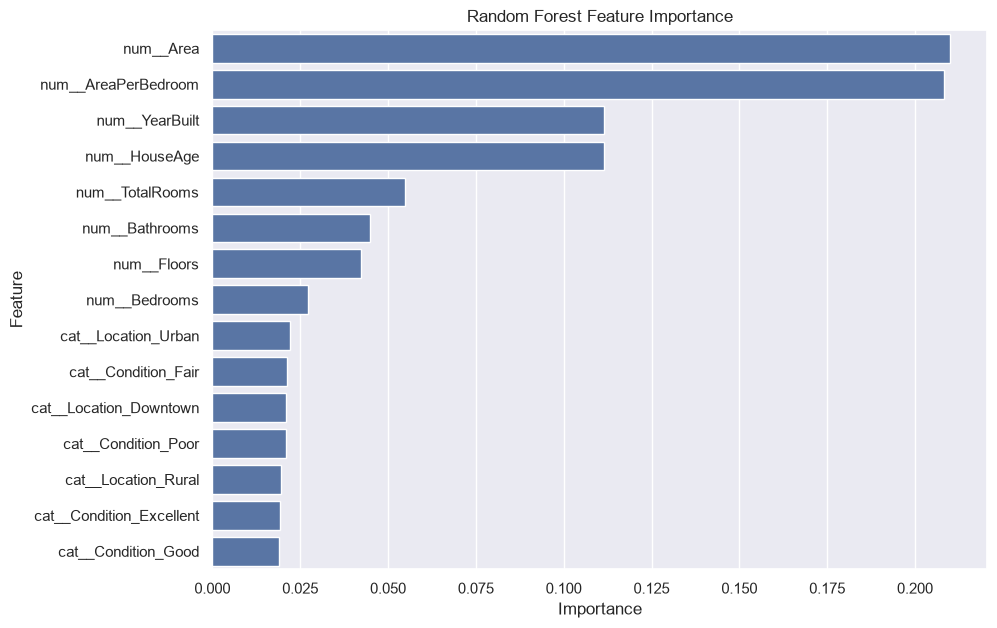

In [50]:
# Visualize the most important features from Random Forest

top_features = importance_df.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.show()

In [51]:
# Train the final Random Forest pipeline on the training data

final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['Area','Bedrooms','Bathrooms',...,'HouseAge','TotalRooms', 'AreaPerBedroom']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of c

In [52]:
# Evaluate the final model on the untouched test dataset

test_predictions = final_model.predict(X_test)

test_results = evaluate_model(
    "Final Random Forest",
    y_test,
    test_predictions
)

pd.DataFrame([test_results])

,Model,MAE,MSE,RMSE,R2 Score
0,Final Random Forest,255330.229083,8.788739e+10,296458.074295,-0.109507


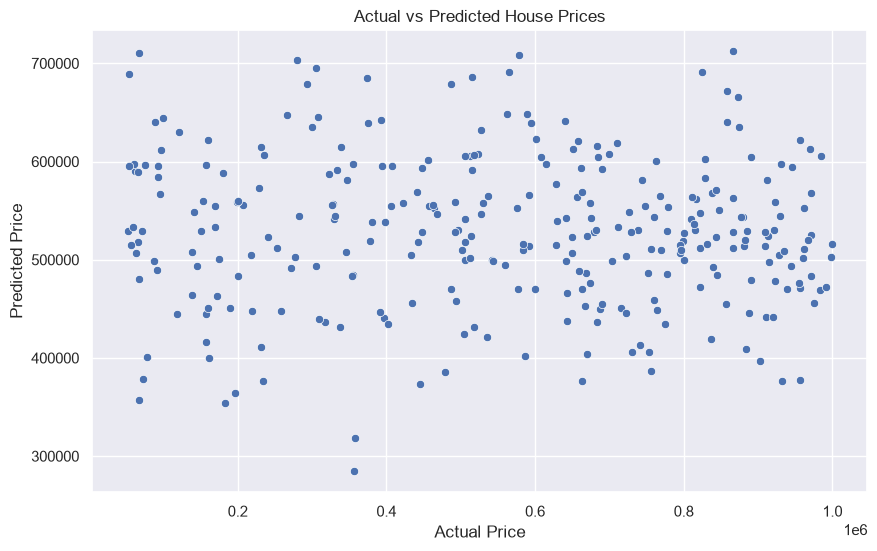

In [53]:
# Compare actual house prices with predicted house prices

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=y_test,
    y=test_predictions
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [54]:
# Save the complete preprocessing and prediction pipeline

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_model,
    "../models/house_price_pipeline.pkl"
)

print("Final pipeline saved successfully.")

Final pipeline saved successfully.


In [55]:
# Save all trained model pipelines

joblib.dump(
    linear_pipeline,
    "../models/linear_regression.pkl"
)

joblib.dump(
    ridge_pipeline,
    "../models/ridge_regression.pkl"
)

joblib.dump(
    random_forest_pipeline,
    "../models/random_forest.pkl"
)

print("All models saved successfully.")

All models saved successfully.


In [56]:
# Load the saved pipeline and verify that it can make predictions

loaded_model = joblib.load(
    "../models/house_price_pipeline.pkl"
)

sample_prediction = loaded_model.predict(
    X_test.head(1)
)

print("Predicted price:", sample_prediction[0])

Predicted price: 588677.94
